# Baselines: cold-start recipe rating prediction

Predict the rating a user with history gives to a recipe on its first rating day. Tune on validation rows with `is_cold_start_eval = 1` (fit on `train.csv`); for test, refit on train + all validation. Metrics: MAE and MSE, with 95% CIs from a user-level bootstrap.

Models: global mean, global median (= 5), shrunk user mean, user median, ingredient TF-IDF + Ridge, Ridge shifted for MAE.

In [1]:
import itertools
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge

pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)


def find_root(start=Path.cwd()):
    """Repo root = first ancestor containing the unzipped data_prepared/shared folder."""
    for p in [start, *start.parents]:
        if (p / "data_prepared" / "shared").is_dir():
            return p
    raise FileNotFoundError("data_prepared/shared not found: unzip the shared data at the repo root")


ROOT = find_root()
SHARED = ROOT / "data_prepared" / "shared"
TEST_LABELS = ROOT / "data_prepared" / "wyt" / "test_labels.csv"
OUT = ROOT / "baseline" / "outputs"
PRED_DIR, METRIC_DIR, TUNING_DIR = OUT / "predictions", OUT / "metrics", OUT / "tuning"
for d in (PRED_DIR, METRIC_DIR, TUNING_DIR):
    d.mkdir(parents=True, exist_ok=True)

STARS = np.arange(1, 6)
USER_K_GRID = [0, 1, 2, 3, 5, 10, 20, 50]
# Two ingredient representations: whole names ("chicken breast") or the words inside them
# ("chicken", "breast"), which lets related ingredients share weight.
ANALYZERS = {
    "whole": lambda ingredients: ingredients,
    "word": lambda ingredients: [w for i in ingredients for w in i.split()],
}
RIDGE_GRID = {"analyzer": ["whole", "word"], "min_df": [2, 5, 20], "alpha": [10, 30, 100, 300, 1000]}
SHIFTS = np.round(np.arange(-1, 1.001, 0.01), 2)

# Test period split: first year after the test start vs later.
TEST_FIRST_YEAR_END = "2013-09-10"
PERIOD_LABELS = ["2012-09-11..2013-09-10", "2013-09-11..2018-12-17"]
TUNED_ON = {"global_mean": "-", "global_median": "-", "user_mean": "MSE (k)", "user_median": "MAE (k)",
            "ridge_tfidf": "MSE", "ridge_tfidf_shifted": "MSE + MAE (shift)"}

# Plot style: recessive axes, thin lines, three categorical colours.
INK2, GRID = "#52514e", "#e6e5e1"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 9,
    "axes.titlesize": 10, "axes.titleweight": "bold",
})

## 1. Data

In [2]:
def read_split(name):
    df = pd.read_csv(SHARED / f"{name}.csv", dtype={"user_id": str, "recipe_id": str})
    parsed = {s: json.loads(s) for s in df["ingredients"].unique()}
    df["ingredients"] = df["ingredients"].map(parsed)
    return df


def load_stage(stage):
    """Return (fit_df, eval_df). eval_df has a `rating` column only in the val stage."""
    train = read_split("train")
    if stage == "val":
        validation = read_split("validation")
        eval_df = validation[validation["is_cold_start_eval"] == 1].reset_index(drop=True)
        return train, eval_df
    if stage == "test":
        validation = read_split("validation").drop(columns="is_cold_start_eval")
        return pd.concat([train, validation], ignore_index=True), read_split("test_features")
    raise ValueError(f"unknown stage: {stage}")


fit_df, eval_df = load_stage("val")
pd.DataFrame({
    name: {"ratings": len(d), "users": d["user_id"].nunique(), "recipes": d["recipe_id"].nunique(),
           "first date": d["date"].min(), "last date": d["date"].max(),
           "share of 5-star": round((d["rating"] == 5).mean(), 3)}
    for name, d in [("train (fit)", fit_df), ("validation cold-start (eval)", eval_df)]
}).T

,ratings,users,recipes,first date,last date,share of 5-star
train (fit),748910,97423,179771,2000-01-25,2010-04-24,0.757
validation cold-start (eval),24252,3695,23893,2010-04-25,2012-09-10,0.761


## 2. Evaluation helpers

In [3]:
def mae(y, p):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p))))


def mse(y, p):
    return float(np.mean((np.asarray(y) - np.asarray(p)) ** 2))


def bootstrap_ci(row_loss, users, n_boot=1000, seed=0):
    """95% CI for the mean of a per-row loss, resampling users (not rows)."""
    loss = pd.Series(np.asarray(row_loss)).groupby(np.asarray(users))
    sums, counts = loss.sum().to_numpy(), loss.count().to_numpy()
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(sums), size=(n_boot, len(sums)))
    boots = sums[idx].sum(axis=1) / counts[idx].sum(axis=1)
    return float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


def test_period(eval_df):
    """Label each test row as first year after the test start or later."""
    first = (eval_df["date"] <= TEST_FIRST_YEAR_END).to_numpy()
    return pd.Categorical(np.where(first, *PERIOD_LABELS), categories=PERIOD_LABELS)


def attach_test_labels(eval_df):
    labels = pd.read_csv(TEST_LABELS)
    assert labels["row_id"].is_unique, "duplicate row_id in test_labels.csv"
    merged = eval_df.merge(labels, on="row_id", how="left", validate="one_to_one")
    assert merged["rating"].notna().all(), "some test rows have no label"
    assert len(labels) == len(eval_df), "test_labels.csv has rows without a prediction"
    return merged


def write_predictions(eval_df, preds, name, stage):
    out = pd.DataFrame({"row_id": eval_df["row_id"], "prediction": preds})
    assert out["row_id"].is_unique and out["prediction"].notna().all()
    out.to_csv(PRED_DIR / f"{stage}_{name}.csv", index=False)


def summarize(name, y, p, users):
    abs_err, sq_err = np.abs(p - y), (p - y) ** 2
    (mae_lo, mae_hi), (mse_lo, mse_hi) = bootstrap_ci(abs_err, users), bootstrap_ci(sq_err, users)
    return {"model": name, "tuned_on": TUNED_ON[name],
            "MAE": abs_err.mean(), "MAE_95CI": f"[{mae_lo:.4f}, {mae_hi:.4f}]",
            "MSE": sq_err.mean(), "MSE_95CI": f"[{mse_lo:.4f}, {mse_hi:.4f}]"}


def by_group(name, y, p, eval_df, groups, group_col):
    groups = pd.Categorical(groups)
    rows = []
    for label in groups.categories:
        m = np.asarray(groups == label)
        rows.append({"model": name, group_col: label, "rows": int(m.sum()),
                     "users": eval_df.loc[m, "user_id"].nunique(),
                     "MAE": mae(y[m], p[m]), "MSE": mse(y[m], p[m])})
    return rows


def score(preds, y, eval_df):
    """Overall MAE / MSE of every model, with user-bootstrap CIs."""
    return pd.DataFrame([summarize(n, y, p, eval_df["user_id"]) for n, p in preds.items()])


def score_by(preds, y, eval_df, groups, group_col):
    """Long table of MAE / MSE per model and group."""
    return pd.DataFrame([r for n, p in preds.items() for r in by_group(n, y, p, eval_df, groups, group_col)])


def wide(grouped, group_col, order):
    """Pivot a long per-group table to models x (metric, group) for display."""
    table = grouped.pivot(index="model", columns=group_col, values=["MAE", "MSE"])
    return table.reindex(index=order, columns=pd.MultiIndex.from_product([["MAE", "MSE"], order_of(grouped, group_col)]))


def order_of(grouped, group_col):
    return list(dict.fromkeys(grouped[group_col]))

## 3. Models

In [4]:
def user_star_counts(fit_df):
    """users x 5 matrix: how many 1..5-star ratings each user gave in the fitting data."""
    return pd.crosstab(fit_df["user_id"], fit_df["rating"]).reindex(columns=STARS, fill_value=0)


def predict_user_mean(counts, users, global_mean, k):
    c = counts.to_numpy(float)
    est = (c @ STARS + k * global_mean) / (c.sum(axis=1) + k)
    return pd.Series(est, index=counts.index).reindex(users).fillna(global_mean).to_numpy()


def predict_user_median(counts, users, global_median, k):
    c = counts.to_numpy(float).copy()
    c[:, int(global_median) - 1] += k
    n, cum = c.sum(axis=1), c.cumsum(axis=1)
    lo, hi = (n - 1) // 2, n // 2  # 0-based middle positions (equal when n is odd)
    v_lo = (cum > lo[:, None]).argmax(axis=1) + 1
    v_hi = (cum > hi[:, None]).argmax(axis=1) + 1
    est = (v_lo + v_hi) / 2  # same convention as np.median for even counts
    return pd.Series(est, index=counts.index).reindex(users).fillna(global_median).to_numpy()


def fit_ridge(fit_df, eval_df, analyzer, min_df, alpha):
    vec = TfidfVectorizer(analyzer=ANALYZERS[analyzer], min_df=min_df)
    vec.fit(fit_df.drop_duplicates("recipe_id")["ingredients"])
    model = Ridge(alpha=alpha, solver="sparse_cg")
    model.fit(vec.transform(fit_df["ingredients"]), fit_df["rating"].to_numpy(float))
    return vec, model, model.predict(vec.transform(eval_df["ingredients"]))


def predict_all(fit_df, eval_df, params, ridge_pred=None):
    """Predictions of every baseline given tuned params (shared by the val and test stages)."""
    y_fit, users = fit_df["rating"].to_numpy(float), eval_df["user_id"]
    g_mean, g_median = y_fit.mean(), float(np.median(y_fit))
    counts = user_star_counts(fit_df)
    if ridge_pred is None:
        r = params["ridge"]
        ridge_pred = fit_ridge(fit_df, eval_df, r["analyzer"], r["min_df"], r["alpha"])[2]
    return {
        "global_mean": np.full(len(eval_df), g_mean),
        "global_median": np.full(len(eval_df), g_median),
        "user_mean": predict_user_mean(counts, users, g_mean, params["user_mean_k"]),
        "user_median": predict_user_median(counts, users, g_median, params["user_median_k"]),
        "ridge_tfidf": ridge_pred,
        "ridge_tfidf_shifted": np.clip(ridge_pred + params["ridge_shift"], 1, 5),
    }

## 4. Validation tuning

### 4.1 User shrinkage `k`

In [5]:
y_fit, y = fit_df["rating"].to_numpy(float), eval_df["rating"].to_numpy(float)
users = eval_df["user_id"]
g_mean, g_median = y_fit.mean(), float(np.median(y_fit))
counts = user_star_counts(fit_df)

user_grid = []
for k in USER_K_GRID:
    pm = predict_user_mean(counts, users, g_mean, k)
    pmed = predict_user_median(counts, users, g_median, k)
    user_grid.append({"k": k, "user_mean_MSE": mse(y, pm), "user_mean_MAE": mae(y, pm),
                      "user_median_MAE": mae(y, pmed), "user_median_MSE": mse(y, pmed),
                      "user_median_share_below_5": float((pmed < 5).mean())})
user_grid = pd.DataFrame(user_grid)
params = {
    "user_mean_k": int(user_grid["k"].iloc[user_grid["user_mean_MSE"].argmin()]),
    "user_median_k": int(user_grid["k"].iloc[user_grid["user_median_MAE"].argmin()]),
}
print("selected:", params)
user_grid

selected: {'user_mean_k': 5, 'user_median_k': 2}


,k,user_mean_MSE,user_mean_MAE,user_median_MAE,user_median_MSE,user_median_share_below_5
0,0,0.3524,0.3869,0.2911,0.4277,0.0952
1,1,0.3359,0.3872,0.2863,0.4180,0.0841
2,2,0.3323,0.3877,0.2842,0.4220,0.0684
3,3,0.3309,0.3883,0.2842,0.4235,0.0648
4,5,0.3301,0.3895,0.2859,0.4303,0.0574
5,10,0.3303,0.3918,0.2865,0.4325,0.0531
6,20,0.3318,0.3950,0.2874,0.4369,0.0449
7,50,0.3348,0.4005,0.2895,0.4414,0.0344


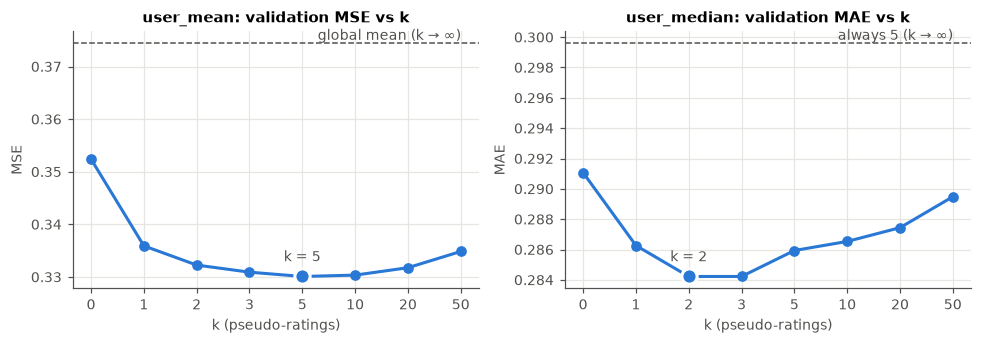

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
xs = np.arange(len(USER_K_GRID))
panels = [("user_mean_MSE", "user_mean_k", mse(y, np.full_like(y, g_mean)), "global mean (k → ∞)",
           "user_mean: validation MSE vs k", "MSE"),
          ("user_median_MAE", "user_median_k", mae(y, np.full_like(y, g_median)), "always 5 (k → ∞)",
           "user_median: validation MAE vs k", "MAE")]
for ax, (col, key, ref, ref_label, title, ylabel) in zip(axes, panels):
    ax.plot(xs, user_grid[col], marker="o", color=BLUE)
    best = USER_K_GRID.index(params[key])
    ax.plot(xs[best], user_grid[col].iloc[best], marker="o", markersize=10, color=BLUE,
            markeredgecolor="white", markeredgewidth=2)
    ax.annotate(f"k = {params[key]}", (xs[best], user_grid[col].iloc[best]),
                textcoords="offset points", xytext=(0, 10), ha="center", color=INK2)
    ax.axhline(ref, color=INK2, linestyle="--", linewidth=1)
    ax.text(xs[-1], ref, ref_label, va="bottom", ha="right", color=INK2)
    ax.set(xticks=xs, xticklabels=USER_K_GRID, xlabel="k (pseudo-ratings)", ylabel=ylabel, title=title)
fig.tight_layout()
plt.show()

### 4.2 Ridge on ingredient TF-IDF

In [7]:
t0 = time.time()
ridge_grid = []
for analyzer, min_df, alpha in itertools.product(*RIDGE_GRID.values()):
    vec, _, p = fit_ridge(fit_df, eval_df, analyzer, min_df, alpha)
    ridge_grid.append({"analyzer": analyzer, "min_df": min_df, "alpha": alpha,
                       "vocab": len(vec.vocabulary_), "MSE": mse(y, p), "MAE": mae(y, p),
                       "pred_std": float(p.std())})
ridge_grid = pd.DataFrame(ridge_grid).sort_values("MSE").reset_index(drop=True)
best = ridge_grid.iloc[0]
params["ridge"] = {"analyzer": best["analyzer"], "min_df": int(best["min_df"]), "alpha": float(best["alpha"])}
print(f"{len(ridge_grid)} fits in {time.time() - t0:.0f}s; selected: {params['ridge']}")
print(f"validation MSE range over the grid: {ridge_grid['MSE'].min():.4f}-{ridge_grid['MSE'].max():.4f} "
      f"(global mean: {mse(y, np.full_like(y, g_mean)):.4f})")
ridge_grid.head(10)

30 fits in 132s; selected: {'analyzer': 'word', 'min_df': 5, 'alpha': 300.0}
validation MSE range over the grid: 0.3695-0.3725 (global mean: 0.3744)


,analyzer,min_df,alpha,vocab,MSE,MAE,pred_std
0,word,5,300,2759,0.3695,0.4649,0.0640
1,word,20,300,1876,0.3695,0.4649,0.0641
2,word,2,300,3498,0.3696,0.4649,0.0639
3,word,5,100,2759,0.3697,0.4641,0.0743
4,word,2,100,3498,0.3697,0.4641,0.0742
5,word,20,100,1876,0.3697,0.4641,0.0744
6,word,20,1000,1876,0.3699,0.4662,0.0499
7,word,5,1000,2759,0.3699,0.4662,0.0497
8,word,2,1000,3498,0.3700,0.4662,0.0497
9,whole,2,100,10367,0.3701,0.4658,0.0718


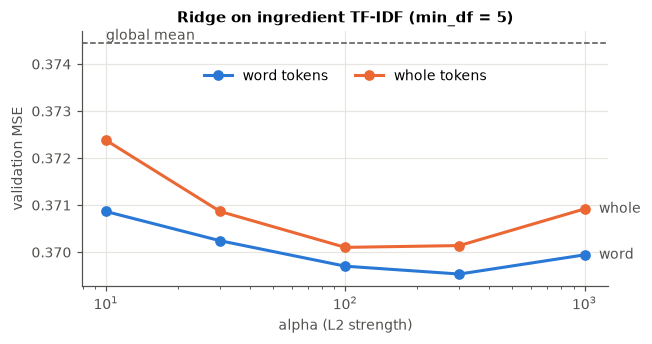

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for analyzer, color in [("word", BLUE), ("whole", ORANGE)]:
    g = ridge_grid[(ridge_grid["analyzer"] == analyzer) & (ridge_grid["min_df"] == 5)].sort_values("alpha")
    ax.plot(g["alpha"], g["MSE"], marker="o", color=color, label=f"{analyzer} tokens")
    ax.text(g["alpha"].iloc[-1] * 1.15, g["MSE"].iloc[-1], analyzer, va="center", color=INK2)
ax.axhline(mse(y, np.full_like(y, g_mean)), color=INK2, linestyle="--", linewidth=1)
ax.text(10, mse(y, np.full_like(y, g_mean)), "global mean", va="bottom", color=INK2)
ax.set(xscale="log", xlabel="alpha (L2 strength)", ylabel="validation MSE",
       title="Ridge on ingredient TF-IDF (min_df = 5)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.9), ncol=2)
fig.tight_layout()
plt.show()

### 4.3 Ridge shift for MAE

selected shift c = +0.65; share of shifted predictions equal to 5: 1.000


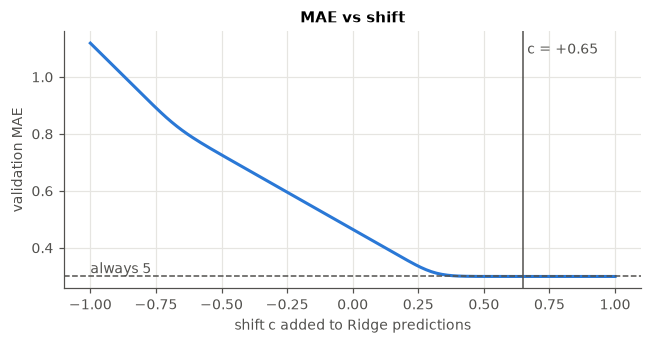

{'user_mean_k': 5,
 'user_median_k': 2,
 'ridge': {'analyzer': 'word', 'min_df': 5, 'alpha': 300.0},
 'ridge_shift': 0.65}

In [9]:
vec, ridge_model, ridge_pred = fit_ridge(fit_df, eval_df, **params["ridge"])
curve = pd.DataFrame({"shift": SHIFTS, "MAE": [mae(y, np.clip(ridge_pred + c, 1, 5)) for c in SHIFTS]})
params["ridge_shift"] = float(curve["shift"].iloc[curve["MAE"].argmin()])
print(f"selected shift c = {params['ridge_shift']:+.2f}; "
      f"share of shifted predictions equal to 5: {(np.clip(ridge_pred + params['ridge_shift'], 1, 5) == 5).mean():.3f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(curve["shift"], curve["MAE"], color=BLUE)
ax.axhline(mae(y, np.full_like(y, 5.0)), color=INK2, linestyle="--", linewidth=1)
ax.text(-1, mae(y, np.full_like(y, 5.0)), "always 5", va="bottom", color=INK2)
ax.axvline(params["ridge_shift"], color=INK2, linewidth=1)
ax.text(params["ridge_shift"], curve["MAE"].max(), f" c = {params['ridge_shift']:+.2f}", va="top", color=INK2)
ax.set(xlabel="shift c added to Ridge predictions", ylabel="validation MAE", title="MAE vs shift")
fig.tight_layout()
plt.show()

(TUNING_DIR / "params.json").write_text(json.dumps(params, indent=2) + "\n")
user_grid.to_csv(TUNING_DIR / "val_user_k_grid.csv", index=False)
ridge_grid.to_csv(TUNING_DIR / "val_ridge_grid.csv", index=False)
curve.to_csv(TUNING_DIR / "val_ridge_shift_curve.csv", index=False)
params

## 5. Validation results

In [10]:
preds = predict_all(fit_df, eval_df, params, ridge_pred)
MODEL_ORDER = list(preds)
val_overall = score(preds, y, eval_df)
for name, p in preds.items():
    write_predictions(eval_df, p, name, "val")
val_overall.to_csv(METRIC_DIR / "val_metrics.csv", index=False)
val_overall

,model,tuned_on,MAE,MAE_95CI,MSE,MSE_95CI
0,global_mean,-,0.4720,"[0.4508, 0.4923]",0.3744,"[0.3338, 0.4190]"
1,global_median,-,0.2996,"[0.2572, 0.3406]",0.4633,"[0.3958, 0.5329]"
2,user_mean,MSE (k),0.3895,"[0.3422, 0.4300]",0.3301,"[0.2847, 0.3752]"
3,user_median,MAE (k),0.2842,"[0.2468, 0.3186]",0.4220,"[0.3626, 0.4799]"
4,ridge_tfidf,MSE,0.4649,"[0.4446, 0.4852]",0.3695,"[0.3297, 0.4122]"
5,ridge_tfidf_shifted,MSE + MAE (shift),0.2996,"[0.2572, 0.3406]",0.4633,"[0.3958, 0.5329]"


**Ridge coefficients**

In [11]:
coefs = (pd.DataFrame({"token": vec.get_feature_names_out(), "coef": ridge_model.coef_})
         .sort_values("coef", ascending=False))
coefs.to_csv(TUNING_DIR / "ridge_coefficients.csv", index=False)
print(f"intercept = {ridge_model.intercept_:.4f}; tokens with |coef| < 0.02: {(coefs['coef'].abs() < 0.02).mean():.0%}")
pd.concat([coefs.head(15).reset_index(drop=True).add_prefix("top_"),
           coefs.tail(15).iloc[::-1].reset_index(drop=True).add_prefix("bottom_")], axis=1)

intercept = 4.6728; tokens with |coef| < 0.02: 68%


,top_token,top_coef,bottom_token,bottom_coef
0,butter,0.1451,sprite,-0.2448
1,bacon,0.1432,tofu,-0.2364
2,strawberries,0.1291,applesauce,-0.2288
3,roast,0.1288,macaroni,-0.2183
4,whipping,0.1258,noodles,-0.2049
5,yeast,0.1224,substitute,-0.1962
6,tortilla,0.1200,rice,-0.1885
7,chipotle,0.1146,chops,-0.1877
8,soda,0.1104,lentils,-0.1691
9,salt,0.1089,penne,-0.1644


## 6. Test

In [12]:
del fit_df, eval_df, counts  # free the validation-stage data
fit_df, test_df = load_stage("test")
test_preds = predict_all(fit_df, test_df, params)
for name, p in test_preds.items():
    write_predictions(test_df, p, name, "test")

test_df = attach_test_labels(test_df)
y_test = test_df["rating"].to_numpy(float)
print(f"fit rows = {len(fit_df):,}; test rows = {len(test_df):,}; test users = {test_df['user_id'].nunique():,}")
test_overall = score(test_preds, y_test, test_df)
test_overall.to_csv(METRIC_DIR / "test_metrics.csv", index=False)
test_overall

fit rows = 909,740; test rows = 11,668; test users = 1,872


,model,tuned_on,MAE,MAE_95CI,MSE,MSE_95CI
0,global_mean,-,0.4771,"[0.4595, 0.4959]",0.4022,"[0.3613, 0.4510]"
1,global_median,-,0.3061,"[0.2746, 0.3392]",0.4955,"[0.4360, 0.5628]"
2,user_mean,MSE (k),0.4026,"[0.3747, 0.4330]",0.3536,"[0.3174, 0.3980]"
3,user_median,MAE (k),0.2935,"[0.2644, 0.3233]",0.4446,"[0.3954, 0.5016]"
4,ridge_tfidf,MSE,0.4661,"[0.4473, 0.4856]",0.3958,"[0.3548, 0.4451]"
5,ridge_tfidf_shifted,MSE + MAE (shift),0.3061,"[0.2746, 0.3392]",0.4955,"[0.4360, 0.5628]"


**Overall vs. time period**

In [13]:
total = score_by(test_preds, y_test, test_df, np.full(len(y_test), "overall"), "period")
periods = score_by(test_preds, y_test, test_df, test_period(test_df), "period")
order = {name: i for i, name in enumerate(MODEL_ORDER)}
test_by_period = (pd.concat([total, periods], ignore_index=True)
                  .sort_values("model", key=lambda s: s.map(order), kind="stable"))
test_by_period.to_csv(METRIC_DIR / "test_metrics_by_period.csv", index=False)
print("rows per group:", test_by_period.drop_duplicates("period").set_index("period")["rows"].to_dict())
wide(test_by_period, "period", MODEL_ORDER)

rows per group: {'overall': 11668, '2012-09-11..2013-09-10': 6449, '2013-09-11..2018-12-17': 5219}


MAE                                                   MSE                                              
                    overall 2012-09-11..2013-09-10 2013-09-11..2018-12-17 overall 2012-09-11..2013-09-10 2013-09-11..2018-12-17
model                                                                                                                          
global_mean          0.4771                 0.4752                 0.4793  0.4022                 0.3892                 0.4182
global_median        0.3061                 0.3061                 0.3062  0.4955                 0.4826                 0.5116
user_mean            0.4026                 0.3983                 0.4078  0.3536                 0.3376                 0.3735
user_median          0.2935                 0.2819                 0.3079  0.4446                 0.4158                 0.4802
ridge_tfidf          0.4661                 0.4645                 0.4680  0.3958                 0.3823                 0.4126
ridge_tfidf_shifted  0.3061                 0.3061                 0.3062  0.4955                 0.4826                 0.5116

In [14]:
(val_overall.set_index("model")[["MAE", "MSE"]]
 .join(test_overall.set_index("model")[["MAE", "MSE"]], lsuffix="_val", rsuffix="_test"))

,MAE_val,MSE_val,MAE_test,MSE_test
model,,,,
global_mean,0.4720,0.3744,0.4771,0.4022
global_median,0.2996,0.4633,0.3061,0.4955
user_mean,0.3895,0.3301,0.4026,0.3536
user_median,0.2842,0.4220,0.2935,0.4446
ridge_tfidf,0.4649,0.3695,0.4661,0.3958
ridge_tfidf_shifted,0.2996,0.4633,0.3061,0.4955
